# Processing Minnesota ERA5 data to use in Ch. 2 Model
Emma Blackford PhD Chapter 2 (2025-2026)

File outputs: regional_lake_index.csv, lakes_with_climate_data_long.csv

In [1]:
# Standard library
import calendar
import time
from io import BytesIO
from pathlib import Path
from zipfile import ZipFile

#packages
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import geopandas as gpd
import matplotlib.dates as mdates
import matplotlib.gridspec as gridspec
import matplotlib.patches as mpatches
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import numpy.linalg as LA
import pandas as pd  # library for data analysis for text files (everything but netcdf files)
import regionmask
import requests
import scipy.io as sio
import scipy.signal as sig
import seaborn as sns
import xarray as xr #package that open and manipulates netcdf files

from cartopy.util import add_cyclic_point
from matplotlib.backends.backend_pdf import PdfPages
from matplotlib.gridspec import GridSpec
from matplotlib.ticker import MaxNLocator
from scipy import stats
from scipy import stats as scipy_stats
from scipy.stats import linregress, pearsonr
from shapely.geometry import Point
from sklearn.decomposition import PCA
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler

# 1. Set up API and download ERA5 data 
**Only run this once

In [2]:
cds_config = """
url: https://cds.climate.copernicus.eu/api
key: 8b28d06f-762d-43bc-960e-7258be38527e
"""

# Write it to the .cdsapirc file in your home directory
with open("/Users/eblckfrd/.cdsapirc", "w") as f:
    f.write(cds_config)

In [5]:
with open("/Users/eblckfrd/.cdsapirc", "r") as f:
    contents = f.read()
print(contents)


url: https://cds.climate.copernicus.eu/api
key: 8b28d06f-762d-43bc-960e-7258be38527e



## Download: Single level monthly average reanalysis: 10m wind speed, top net solar radiation downward, top net thermal radiation downward

In [6]:
import cdsapi

dataset = "reanalysis-era5-single-levels-monthly-means"
request = {
    "product_type": ["monthly_averaged_reanalysis"],
    "variable": [
        "10m_wind_speed",
        "top_net_solar_radiation",
        "top_net_thermal_radiation"
    ],
    "year": [
        "1980", "1981", "1982",
        "1983", "1984", "1985",
        "1986", "1987", "1988",
        "1989", "1990", "1991",
        "1992", "1993", "1994",
        "1995", "1996", "1997",
        "1998", "1999", "2000",
        "2001", "2002", "2003",
        "2004", "2005", "2006",
        "2007", "2008", "2009",
        "2010", "2011", "2012",
        "2013", "2014", "2015",
        "2016", "2017", "2018",
        "2019", "2020"
    ],
    "month": [
        "05", "06", "07",
        "08", "09"
    ],
    "time": ["00:00"],
    "data_format": "netcdf",
    "download_format": "unarchived",
    "area": [51, -100, 39, -82]
}

client = cdsapi.Client()
client.retrieve(dataset, request).download()

2025-10-02 14:34:25,070 INFO Request ID is a7acd78a-1b0d-4874-a080-72bd286f92d9
2025-10-02 14:34:25,236 INFO status has been updated to accepted
2025-10-02 14:34:34,054 INFO status has been updated to running
2025-10-02 14:35:42,040 INFO status has been updated to successful


eea67d313607dd91e30a36dd7403b64.zip:   0%|          | 0.00/3.34M [00:00<?, ?B/s]

'eea67d313607dd91e30a36dd7403b64.zip'

In [8]:
import zipfile

zip_path = "eea67d313607dd91e30a36dd7403b64.zip"
with zipfile.ZipFile(zip_path, "r") as z:
    z.extractall("era5_data")

## Download: ERA5-Land 2m air temperature and total precipitation

In [7]:
import cdsapi

dataset = "reanalysis-era5-land-monthly-means"
request = {
    "product_type": ["monthly_averaged_reanalysis"],
    "variable": [
        "2m_temperature",
        "total_precipitation"
    ],
    "year": [
        "1980", "1981", "1982",
        "1983", "1984", "1985",
        "1986", "1987", "1988",
        "1989", "1990", "1991",
        "1992", "1993", "1994",
        "1995", "1996", "1997",
        "1998", "1999", "2000",
        "2001", "2002", "2003",
        "2004", "2005", "2006",
        "2007", "2008", "2009",
        "2010", "2011", "2012",
        "2013", "2014", "2015",
        "2016", "2017", "2018",
        "2019", "2020"
    ],
    "month": ["04", "05", "06", "07", "08"],
    "time": ["00:00"],
    "data_format": "netcdf",
    "download_format": "unarchived",
    "area": [51, -100, 39, -82]
}

client = cdsapi.Client()
client.retrieve(dataset, request).download()

2026-03-09 14:35:09,338 INFO Request ID is 99375aef-5f6c-4628-ad3b-81b2b1c02629
2026-03-09 14:35:09,520 INFO status has been updated to accepted
2026-03-09 14:35:23,835 INFO status has been updated to running
2026-03-09 14:36:26,717 INFO status has been updated to successful


'f34dabcdec2092dbe9f1dd7164121e08.nc'

## Download: Pressure level monthly average reanalysis: geopotential height, u-winds, v-winds at 500mb

Using an expanded boundary for the pressure levels data-- need to capture jet stream and rossby wave behavior

In [81]:
import cdsapi

dataset = "reanalysis-era5-pressure-levels-monthly-means"
request = {
    "product_type": ["monthly_averaged_reanalysis"],
    "variable": [
        "geopotential",
        "u_component_of_wind",
        "v_component_of_wind"
    ],
    "pressure_level": ["500"],
    "year": [
        "1980", "1981", "1982",
        "1983", "1984", "1985",
        "1986", "1987", "1988",
        "1989", "1990", "1991",
        "1992", "1993", "1994",
        "1995", "1996", "1997",
        "1998", "1999", "2000",
        "2001", "2002", "2003",
        "2004", "2005", "2006",
        "2007", "2008", "2009",
        "2010", "2011", "2012",
        "2013", "2014", "2015",
        "2016", "2017", "2018",
        "2019", "2020"
    ],
    "month": [
        "05", "06", "07",
        "08", "09"
    ],
    "time": ["00:00"],
    "data_format": "netcdf",
    "download_format": "unarchived",
    "area": [70, -130, 25, -60]
}

client = cdsapi.Client()
client.retrieve(dataset, request).download()

2025-10-07 14:26:46,509 INFO Request ID is c0161436-a107-4612-92c9-5d3c4450cbe8
2025-10-07 14:26:46,691 INFO status has been updated to accepted
2025-10-07 14:27:00,742 INFO status has been updated to running
2025-10-07 14:28:03,246 INFO status has been updated to successful


'c5ba46cd43b3e536dc0079d52b793149.nc'

# 2. Put all data into correct formats for export

In [3]:
ds = xr.open_dataset("era5_data/data_stream-moda_stepType-avgua.nc")
print(ds)

#si10 = 10m_wind_speed

<xarray.Dataset> Size: 3MB
Dimensions:     (valid_time: 205, latitude: 49, longitude: 73)
Coordinates:
  * valid_time  (valid_time) datetime64[ns] 2kB 1980-05-01 ... 2020-09-01
  * latitude    (latitude) float64 392B 51.0 50.75 50.5 ... 39.5 39.25 39.0
  * longitude   (longitude) float64 584B -100.0 -99.75 -99.5 ... -82.25 -82.0
    number      int64 8B ...
    expver      (valid_time) <U4 3kB ...
Data variables:
    si10        (valid_time, latitude, longitude) float32 3MB ...
Attributes:
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             European Centre for Medium-Range Weather Forecasts
    history:                 2025-10-02T19:35 GRIB to CDM+CF via cfgrib-0.9.1...


In [4]:
windspeed = ds.si10
print(windspeed)


<xarray.DataArray 'si10' (valid_time: 205, latitude: 49, longitude: 73)> Size: 3MB
[733285 values with dtype=float32]
Coordinates:
  * valid_time  (valid_time) datetime64[ns] 2kB 1980-05-01 ... 2020-09-01
  * latitude    (latitude) float64 392B 51.0 50.75 50.5 ... 39.5 39.25 39.0
  * longitude   (longitude) float64 584B -100.0 -99.75 -99.5 ... -82.25 -82.0
    number      int64 8B ...
    expver      (valid_time) <U4 3kB ...
Attributes: (12/32)
    GRIB_paramId:                             207
    GRIB_dataType:                            an
    GRIB_numberOfPoints:                      3577
    GRIB_typeOfLevel:                         surface
    GRIB_stepUnits:                           1
    GRIB_stepType:                            avgua
    ...                                       ...
    GRIB_totalNumber:                         0
    GRIB_units:                               m s**-1
    long_name:                                10 metre wind speed
    units:                   

In [5]:
dp = xr.open_dataset("era5_data/data_stream-moda_stepType-avgad.nc")
print(dp)

#tsr = top net solar radiation
#ttr = top net thermal radiation

<xarray.Dataset> Size: 6MB
Dimensions:     (valid_time: 205, latitude: 49, longitude: 73)
Coordinates:
  * valid_time  (valid_time) datetime64[ns] 2kB 1980-05-01T06:00:00 ... 2020-...
  * latitude    (latitude) float64 392B 51.0 50.75 50.5 ... 39.5 39.25 39.0
  * longitude   (longitude) float64 584B -100.0 -99.75 -99.5 ... -82.25 -82.0
    number      int64 8B ...
    expver      (valid_time) <U4 3kB ...
Data variables:
    tsr         (valid_time, latitude, longitude) float32 3MB ...
    ttr         (valid_time, latitude, longitude) float32 3MB ...
Attributes:
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             European Centre for Medium-Range Weather Forecasts
    history:                 2025-10-02T19:35 GRIB to CDM+CF via cfgrib-0.9.1...


In [6]:
tsr = dp.tsr
ttr = dp.ttr

print(tsr)
#print(ttr)

<xarray.DataArray 'tsr' (valid_time: 205, latitude: 49, longitude: 73)> Size: 3MB
[733285 values with dtype=float32]
Coordinates:
  * valid_time  (valid_time) datetime64[ns] 2kB 1980-05-01T06:00:00 ... 2020-...
  * latitude    (latitude) float64 392B 51.0 50.75 50.5 ... 39.5 39.25 39.0
  * longitude   (longitude) float64 584B -100.0 -99.75 -99.5 ... -82.25 -82.0
    number      int64 8B ...
    expver      (valid_time) <U4 3kB ...
Attributes: (12/32)
    GRIB_paramId:                             178
    GRIB_dataType:                            fc
    GRIB_numberOfPoints:                      3577
    GRIB_typeOfLevel:                         surface
    GRIB_stepUnits:                           1
    GRIB_stepType:                            avgad
    ...                                       ...
    GRIB_totalNumber:                         0
    GRIB_units:                               J m**-2
    long_name:                                Top net short-wave (solar) radi...
    unit

In [7]:
dr = xr.open_dataset("c5ba46cd43b3e536dc0079d52b793149.nc")
print(dr)

#z = geopotential height
#u = u-winds
#v = v-winds

<xarray.Dataset> Size: 125MB
Dimensions:         (valid_time: 205, pressure_level: 1, latitude: 181,
                     longitude: 281)
Coordinates:
  * valid_time      (valid_time) datetime64[ns] 2kB 1980-05-01 ... 2020-09-01
  * pressure_level  (pressure_level) float64 8B 500.0
  * latitude        (latitude) float64 1kB 70.0 69.75 69.5 ... 25.5 25.25 25.0
  * longitude       (longitude) float64 2kB -130.0 -129.8 ... -60.25 -60.0
    number          int64 8B ...
    expver          (valid_time) <U4 3kB ...
Data variables:
    z               (valid_time, pressure_level, latitude, longitude) float32 42MB ...
    u               (valid_time, pressure_level, latitude, longitude) float32 42MB ...
    v               (valid_time, pressure_level, latitude, longitude) float32 42MB ...
Attributes:
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution

In [8]:
geoheight = dr.z
uwinds = dr.u
vwinds = dr.v

print(geoheight)
#print(uwinds)


<xarray.DataArray 'z' (valid_time: 205, pressure_level: 1, latitude: 181,
                       longitude: 281)> Size: 42MB
[10426505 values with dtype=float32]
Coordinates:
  * valid_time      (valid_time) datetime64[ns] 2kB 1980-05-01 ... 2020-09-01
  * pressure_level  (pressure_level) float64 8B 500.0
  * latitude        (latitude) float64 1kB 70.0 69.75 69.5 ... 25.5 25.25 25.0
  * longitude       (longitude) float64 2kB -130.0 -129.8 ... -60.25 -60.0
    number          int64 8B ...
    expver          (valid_time) <U4 3kB ...
Attributes: (12/31)
    GRIB_paramId:                             129
    GRIB_dataType:                            an
    GRIB_numberOfPoints:                      50861
    GRIB_typeOfLevel:                         isobaricInhPa
    GRIB_stepUnits:                           1
    GRIB_stepType:                            avgua
    ...                                       ...
    GRIB_shortName:                           z
    GRIB_totalNumber:           

In [9]:
dt = xr.open_dataset("f34dabcdec2092dbe9f1dd7164121e08.nc")
print(dt)

#t2m = air temp at 2m
#tp = total precipitation

<xarray.Dataset> Size: 36MB
Dimensions:     (valid_time: 205, latitude: 121, longitude: 181)
Coordinates:
  * valid_time  (valid_time) datetime64[ns] 2kB 1980-04-01 ... 2020-08-01
  * latitude    (latitude) float64 968B 51.0 50.9 50.8 50.7 ... 39.2 39.1 39.0
  * longitude   (longitude) float64 1kB -100.0 -99.9 -99.8 ... -82.2 -82.1 -82.0
    number      int64 8B ...
    expver      (valid_time) <U4 3kB ...
Data variables:
    t2m         (valid_time, latitude, longitude) float32 18MB ...
    tp          (valid_time, latitude, longitude) float32 18MB ...
Attributes:
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             European Centre for Medium-Range Weather Forecasts
    history:                 2026-03-09T19:36 GRIB to CDM+CF via cfgrib-0.9.1...


In [10]:
airtemp = dt.t2m
precip = dt.tp

#verify units before converting
print(precip.attrs)  # look for 'units' key

#print(airtemp)
#print(precip)

days_array = np.array([
    calendar.monthrange(pd.Timestamp(t.values).year,
                        pd.Timestamp(t.values).month)[1]
    for t in precip.valid_time
])

totalprecip = precip * xr.DataArray(
    days_array,
    coords={'valid_time': precip.valid_time},
    dims=['valid_time']
)

print(f"Monthly precip range: {float(totalprecip.min()):.4f} – {float(totalprecip.max()):.4f} m")
print(f"Mean monthly precip:  {float(totalprecip.mean()):.4f} m")

#expect mean ~0.06–0.12 m (6–12 cm/month) for Apr–Aug Upper Midwest

{'GRIB_paramId': np.int64(228), 'GRIB_dataType': 'fc', 'GRIB_numberOfPoints': np.int64(21901), 'GRIB_typeOfLevel': 'surface', 'GRIB_stepUnits': np.int64(1), 'GRIB_gridType': 'regular_ll', 'GRIB_uvRelativeToGrid': np.int64(0), 'GRIB_NV': np.int64(0), 'GRIB_Nx': np.int64(181), 'GRIB_Ny': np.int64(121), 'GRIB_cfName': 'unknown', 'GRIB_cfVarName': 'tp', 'GRIB_gridDefinitionDescription': 'Latitude/Longitude Grid', 'GRIB_iDirectionIncrementInDegrees': np.float64(0.1), 'GRIB_iScansNegatively': np.int64(0), 'GRIB_jDirectionIncrementInDegrees': np.float64(0.1), 'GRIB_jPointsAreConsecutive': np.int64(0), 'GRIB_jScansPositively': np.int64(0), 'GRIB_latitudeOfFirstGridPointInDegrees': np.float64(51.0), 'GRIB_latitudeOfLastGridPointInDegrees': np.float64(39.0), 'GRIB_longitudeOfFirstGridPointInDegrees': np.float64(-100.0), 'GRIB_longitudeOfLastGridPointInDegrees': np.float64(-82.0), 'GRIB_missingValue': np.float64(3.4028234663852886e+38), 'GRIB_name': 'Total precipitation', 'GRIB_shortName': 'tp', 

## Trim windspeed, ttr, tsr down to Minnesota using polygon mask, then average seasonally and export as .csv

In [11]:
#states set that exists across versions
try:
    STATES = regionmask.defined_regions.natural_earth_v5_0_0.us_states_50
except AttributeError:
    STATES = regionmask.defined_regions.natural_earth.us_states_50

mn_idx = [i for i, n in enumerate(STATES.names) if n == "Minnesota"][0]

#find lon/lat coord names from the dataset or the windspeed DataArray
def find_coord(da_or_ds, candidates):
    for c in candidates:
        if c in getattr(da_or_ds, "coords", {}):
            return c
        if c in getattr(da_or_ds, "dims", ()):
            return c
    raise KeyError("Could not find any of: " + ", ".join(candidates))

lon_name = find_coord(windspeed, ["longitude", "lon", "x"])
lat_name = find_coord(windspeed, ["latitude", "lat", "y"])

#get 1-D lon/lat arrays
lon = windspeed[lon_name]
lat = windspeed[lat_name]

#convert longitudes to [-180, 180)
if float(lon.max()) > 180:
    lon_new = ((lon + 180) % 360) - 180
    order = np.argsort(lon_new)
    lon = lon_new[order]
    windspeed = windspeed.isel({lon_name: order})

#Ensure latitude is monotonic; usually ERA5 latitude is descending

#build mask passing lon/lat explicitly
mask = STATES.mask(lon, lat) 

#align mask coords/names  so broadcasting works
mask = mask.rename({mask.dims[0]: lat_name, mask.dims[1]: lon_name})
mask = mask.assign_coords({lat_name: windspeed[lat_name], lon_name: windspeed[lon_name]})

#apply mask to keep only Minnesota cells
mn_windspeed = windspeed.where(mask == mn_idx, drop=True)
print(mn_windspeed)

<xarray.DataArray 'si10' (valid_time: 205, latitude: 23, longitude: 30)> Size: 566kB
array([[[      nan,       nan,       nan, ...,       nan,       nan,
               nan],
        [      nan,       nan,       nan, ...,       nan,       nan,
               nan],
        [4.161331 , 4.0578156, 3.888382 , ...,       nan,       nan,
               nan],
        ...,
        [      nan,       nan,       nan, ...,       nan,       nan,
               nan],
        [      nan,       nan,       nan, ...,       nan,       nan,
               nan],
        [      nan,       nan,       nan, ...,       nan,       nan,
               nan]],

       [[      nan,       nan,       nan, ...,       nan,       nan,
               nan],
        [      nan,       nan,       nan, ...,       nan,       nan,
               nan],
        [4.338112 , 4.2624283, 4.1530533, ...,       nan,       nan,
               nan],
...
        [      nan,       nan,       nan, ...,       nan,       nan,
               na

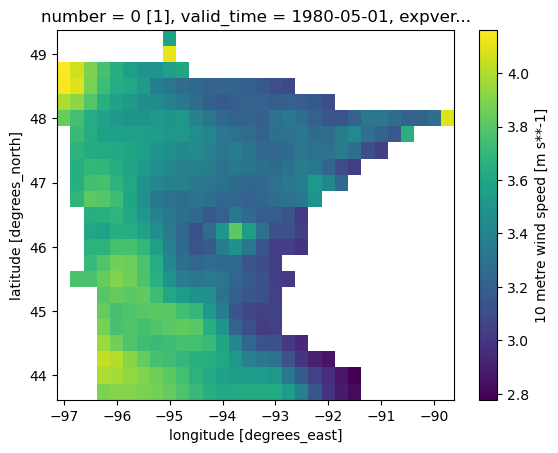

In [12]:
# pick one time slice to test that map worked

mn_windspeed.isel(valid_time=0).plot(cmap="viridis")
plt.show()

In [13]:
#repeat for tsr and ttr

def find_coord(da_or_ds, candidates):
    for c in candidates:
        if c in getattr(da_or_ds, "coords", {}):
            return c
        if c in getattr(da_or_ds, "dims", ()):
            return c
    raise KeyError("Could not find any of: " + ", ".join(candidates))

lon_name = find_coord(tsr, ["longitude", "lon", "x"])
lat_name = find_coord(tsr, ["latitude", "lat", "y"])

lon = tsr[lon_name]
lat = tsr[lat_name]

if float(lon.max()) > 180:
    lon_new = ((lon + 180) % 360) - 180
    order = np.argsort(lon_new)
    lon = lon_new[order]
    tsr = tsr.isel({lon_name: order})

mask = STATES.mask(lon, lat)  # dims: (lat, lon) but names may be generic
mask = mask.rename({mask.dims[0]: lat_name, mask.dims[1]: lon_name})
mask = mask.assign_coords({lat_name: tsr[lat_name], lon_name: tsr[lon_name]})

mn_tsr = tsr.where(mask == mn_idx, drop=True)
print(mn_tsr)


<xarray.DataArray 'tsr' (valid_time: 205, latitude: 23, longitude: 30)> Size: 566kB
array([[[          nan,           nan,           nan, ...,
                   nan,           nan,           nan],
        [          nan,           nan,           nan, ...,
                   nan,           nan,           nan],
        [2.9121536e+07, 2.8925952e+07, 2.8935168e+07, ...,
                   nan,           nan,           nan],
        ...,
        [          nan,           nan,           nan, ...,
                   nan,           nan,           nan],
        [          nan,           nan,           nan, ...,
                   nan,           nan,           nan],
        [          nan,           nan,           nan, ...,
                   nan,           nan,           nan]],

       [[          nan,           nan,           nan, ...,
                   nan,           nan,           nan],
        [          nan,           nan,           nan, ...,
                   nan,           nan,      

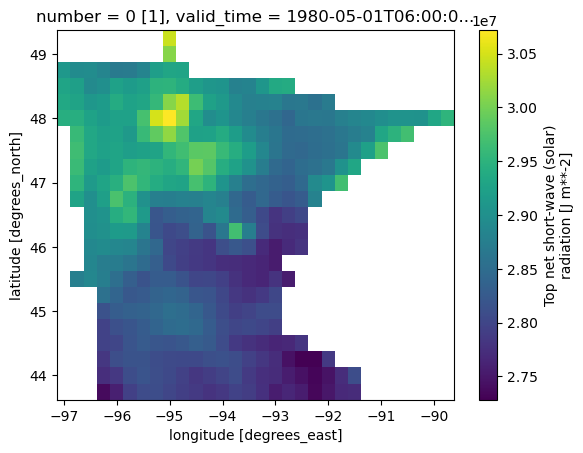

In [14]:
# pick one time slice to test that map worked

mn_tsr.isel(valid_time=0).plot(cmap="viridis")
plt.show()

In [15]:
#now for ttr

def find_coord(da_or_ds, candidates):
    for c in candidates:
        if c in getattr(da_or_ds, "coords", {}):
            return c
        if c in getattr(da_or_ds, "dims", ()):
            return c
    raise KeyError("Could not find any of: " + ", ".join(candidates))

lon_name = find_coord(ttr, ["longitude", "lon", "x"])
lat_name = find_coord(ttr, ["latitude", "lat", "y"])

lon = ttr[lon_name]
lat = ttr[lat_name]

if float(lon.max()) > 180:
    lon_new = ((lon + 180) % 360) - 180
    order = np.argsort(lon_new)
    lon = lon_new[order]
    ttr = ttr.isel({lon_name: order})

mask = STATES.mask(lon, lat)
mask = mask.rename({mask.dims[0]: lat_name, mask.dims[1]: lon_name})
mask = mask.assign_coords({lat_name: ttr[lat_name], lon_name: ttr[lon_name]})

mn_ttr = ttr.where(mask == mn_idx, drop=True)
print(mn_ttr)

<xarray.DataArray 'ttr' (valid_time: 205, latitude: 23, longitude: 30)> Size: 566kB
array([[[           nan,            nan,            nan, ...,
                    nan,            nan,            nan],
        [           nan,            nan,            nan, ...,
                    nan,            nan,            nan],
        [-2.1622528e+07, -2.1585152e+07, -2.1500160e+07, ...,
                    nan,            nan,            nan],
        ...,
        [           nan,            nan,            nan, ...,
                    nan,            nan,            nan],
        [           nan,            nan,            nan, ...,
                    nan,            nan,            nan],
        [           nan,            nan,            nan, ...,
                    nan,            nan,            nan]],

       [[           nan,            nan,            nan, ...,
                    nan,            nan,            nan],
        [           nan,            nan,            nan, ...,

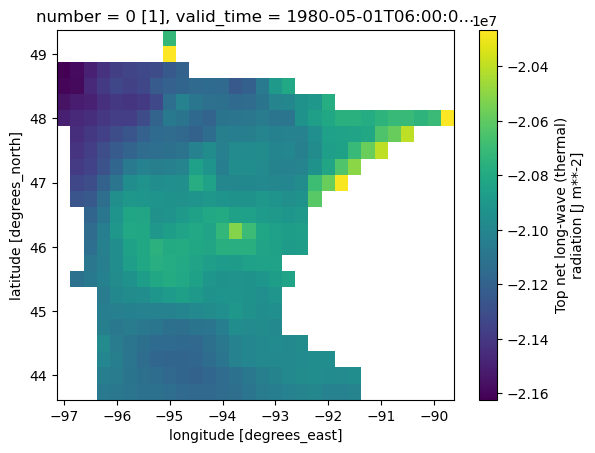

In [16]:
# pick one time slice to test that map worked

mn_ttr.isel(valid_time=0).plot(cmap="viridis")
plt.show()

In [17]:
#combine windspeed, ttr, and tsr data into one dataset

MN_climate1 = xr.merge([
    mn_ttr.rename('ttr'),
    mn_tsr.rename('tsr'),
    mn_windspeed.rename('windspeed')
])

print(MN_climate1)

<xarray.Dataset> Size: 3MB
Dimensions:     (valid_time: 410, latitude: 23, longitude: 30)
Coordinates:
  * valid_time  (valid_time) datetime64[ns] 3kB 1980-05-01 ... 2020-09-01T06:...
  * latitude    (latitude) float64 184B 49.25 49.0 48.75 ... 44.25 44.0 43.75
  * longitude   (longitude) float64 240B -97.0 -96.75 -96.5 ... -90.0 -89.75
    number      int64 8B 0
    expver      (valid_time) object 3kB '0001' '0001' '0001' ... '0001' '0001'
Data variables:
    ttr         (valid_time, latitude, longitude) float32 1MB nan nan ... nan
    tsr         (valid_time, latitude, longitude) float32 1MB nan nan ... nan
    windspeed   (valid_time, latitude, longitude) float32 1MB nan nan ... nan
Attributes: (12/32)
    GRIB_paramId:                             179
    GRIB_dataType:                            fc
    GRIB_numberOfPoints:                      3577
    GRIB_typeOfLevel:                         surface
    GRIB_stepUnits:                           1
    GRIB_stepType:               

/var/folders/19/t4rdrpl920vb3nzs84k5ywtc0000gn/T/ipykernel_74788/2486854856.py:3: FutureWarning: In a future version of xarray the default value for join will change from join='outer' to join='exact'. This change will result in the following ValueError: cannot be aligned with join='exact' because index/labels/sizes are not equal along these coordinates (dimensions): 'valid_time' ('valid_time',) The recommendation is to set join explicitly for this case.
  MN_climate1 = xr.merge([
/var/folders/19/t4rdrpl920vb3nzs84k5ywtc0000gn/T/ipykernel_74788/2486854856.py:3: FutureWarning: In a future version of xarray the default value for compat will change from compat='no_conflicts' to compat='override'. This is likely to lead to different results when combining overlapping variables with the same name. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set compat explicitly.
  MN_climate1 = xr.merge([
/var/folders/19/t4rdrpl920vb3n

In [18]:
#add year and month coordinates for easier grouping
MN_climate1 = MN_climate1.assign_coords(
    year=MN_climate1['valid_time'].dt.year,
    month=MN_climate1['valid_time'].dt.month
)

#extract specific months/seasons for each variable
# May only (month 5)
may_data = MN_climate1.where(MN_climate1['month'] == 5, drop=True).groupby('year').mean(dim='valid_time')

# June only (months 6)
june_data = MN_climate1.where(MN_climate1['month'] == 6, drop=True).groupby('year').mean(dim='valid_time')

# August only (month 8)
august_data = MN_climate1.where(MN_climate1['month'] == 8, drop=True).groupby('year').mean(dim='valid_time')

# July-August average (months 7-8)
ja_data = MN_climate1.where(MN_climate1['month'].isin([7, 8]), drop=True).groupby('year').mean(dim='valid_time')


In [19]:
#combine all into one dataset
final_ds = xr.Dataset({
    'ttr_may': may_data['ttr'],
    'ttr_june': june_data['ttr'],
    'ttr_august': august_data['ttr'],
    'ttr_ja': ja_data['ttr'],
    'tsr_may': may_data['tsr'],
    'tsr_june': june_data['tsr'],
    'tsr_august': august_data['tsr'],
    'tsr_ja': ja_data['tsr'],
    'windspeed_may': may_data['windspeed'],
    'windspeed_june': june_data['windspeed'],
    'windspeed_august': august_data['windspeed'],
    'windspeed_ja': ja_data['windspeed']
})

print("Final dataset structure:")
print(final_ds)

Final dataset structure:
<xarray.Dataset> Size: 1MB
Dimensions:           (latitude: 23, longitude: 30, year: 41)
Coordinates:
  * latitude          (latitude) float64 184B 49.25 49.0 48.75 ... 44.0 43.75
  * longitude         (longitude) float64 240B -97.0 -96.75 ... -90.0 -89.75
  * year              (year) int64 328B 1980 1981 1982 1983 ... 2018 2019 2020
    number            int64 8B 0
Data variables:
    ttr_may           (year, latitude, longitude) float32 113kB nan nan ... nan
    ttr_june          (year, latitude, longitude) float32 113kB nan nan ... nan
    ttr_august        (year, latitude, longitude) float32 113kB nan nan ... nan
    ttr_ja            (year, latitude, longitude) float32 113kB nan nan ... nan
    tsr_may           (year, latitude, longitude) float32 113kB nan nan ... nan
    tsr_june          (year, latitude, longitude) float32 113kB nan nan ... nan
    tsr_august        (year, latitude, longitude) float32 113kB nan nan ... nan
    tsr_ja            (year, l

In [20]:
#convert to DataFrame and drop NaNs
df = final_ds.to_dataframe().reset_index()
df_clean = df.dropna(subset=['ttr_may', 'ttr_june', 'ttr_august', 'ttr_ja',
                               'tsr_may', 'tsr_june', 'tsr_august', 'tsr_ja',
                               'windspeed_may', 'windspeed_june', 'windspeed_august', 'windspeed_ja'], 
                      how='any')

print(f"\nOriginal size: {len(df)} rows")
print(f"After removing NaNs: {len(df_clean)} rows")
print(f"Rows removed: {len(df) - len(df_clean)}")


Original size: 28290 rows
After removing NaNs: 16072 rows
Rows removed: 12218


In [21]:
#preview cleaned data
print("\nFirst few rows:")
print(df_clean.head())


First few rows:
     latitude  longitude  year  number     ttr_may    ttr_june  ttr_august  \
328     49.25      -95.0  1980       0 -20721920.0 -20917568.0 -21014192.0   
329     49.25      -95.0  1981       0 -19813840.0 -20227904.0 -21947552.0   
330     49.25      -95.0  1982       0 -19231472.0 -20622528.0 -21726464.0   
331     49.25      -95.0  1983       0 -19534352.0 -20349968.0 -22766416.0   
332     49.25      -95.0  1984       0 -19588400.0 -20300960.0 -22931984.0   

         ttr_ja     tsr_may    tsr_june  tsr_august      tsr_ja  \
328 -21350648.0  30437376.0  30422016.0  23366656.0  26910720.0   
329 -22347752.0  28833792.0  28310528.0  24773632.0  27577344.0   
330 -21246456.0  25367552.0  29273088.0  25276416.0  27085824.0   
331 -22369584.0  28316672.0  28551168.0  26635264.0  28011008.0   
332 -22151856.0  28529664.0  28319744.0  26590208.0  28485632.0   

     windspeed_may  windspeed_june  windspeed_august  windspeed_ja  
328       3.576370        4.275124        

In [23]:
#export
df_clean.to_csv('MN_seasonalclimate.csv', index=False)

## Now work with pressure level data

### Look at maps of climatology for may and june data

In [11]:
#calculate climatology each month using groupby
climo = geoheight.groupby('valid_time.month').mean('valid_time') 
climo2 = uwinds.groupby('valid_time.month').mean('valid_time') 
climo3 = vwinds.groupby('valid_time.month').mean('valid_time') 

In [12]:
#group the original data by month and remove each month's climatological mean
norm_geoheight = geoheight.groupby('valid_time.month')-climo
norm_uwinds = uwinds.groupby('valid_time.month')-climo2
norm_vwinds = vwinds.groupby('valid_time.month')-climo3

In [13]:
#isolate month of May and June
may_hgt = norm_geoheight.sel(valid_time=norm_geoheight.valid_time.dt.month == 5)
june_hgt = norm_geoheight.sel(valid_time=norm_geoheight.valid_time.dt.month == 6)
july_hgt = norm_geoheight.sel(valid_time=norm_geoheight.valid_time.dt.month == 7)

may_uwinds = norm_uwinds.sel(valid_time=norm_uwinds.valid_time.dt.month == 5)
june_uwinds = norm_uwinds.sel(valid_time=norm_uwinds.valid_time.dt.month == 6)

may_vwinds = norm_vwinds.sel(valid_time=norm_vwinds.valid_time.dt.month == 5)
june_vwinds = norm_vwinds.sel(valid_time=norm_vwinds.valid_time.dt.month == 6)

In [14]:
may_hgt = may_hgt[:, 0, :, :]
june_hgt = june_hgt[:, 0, :, :]

may_uwinds = may_uwinds[:, 0, :, :]
june_uwinds = june_uwinds[:, 0, :, :]

may_vwinds = may_vwinds[:, 0, :, :]
june_vwinds = june_vwinds [:, 0, :, :]

In [28]:
print(june_vwinds)

<xarray.DataArray 'v' (valid_time: 41, latitude: 181, longitude: 281)> Size: 8MB
array([[[ 2.6741982e-01,  1.7113316e-01,  8.0562949e-02, ...,
          4.3172598e+00,  4.4028759e+00,  4.4846334e+00],
        [ 2.9011893e-01,  1.9109309e-01,  9.6056938e-02, ...,
          4.1196012e+00,  4.1970358e+00,  4.2718735e+00],
        [ 3.0819750e-01,  2.0450294e-01,  1.0461974e-01, ...,
          3.9354599e+00,  4.0047960e+00,  4.0731907e+00],
        ...,
        [ 3.2127559e+00,  3.1639516e+00,  3.1206851e+00, ...,
          3.4402337e-02,  2.7363941e-02,  3.9308965e-02],
        [ 3.0226717e+00,  2.9799173e+00,  2.9430342e+00, ...,
          3.7001669e-03,  3.3428818e-03,  1.6669393e-02],
        [ 2.8388755e+00,  2.8073516e+00,  2.7733862e+00, ...,
         -2.3214854e-02, -3.1122625e-02, -3.2242104e-02]],

       [[ 2.9783630e-01,  2.7381527e-01,  2.4672163e-01, ...,
         -2.5893352e+00, -2.6487389e+00, -2.7105360e+00],
        [ 2.8440261e-01,  2.5129473e-01,  2.1534061e-01, ...,
  

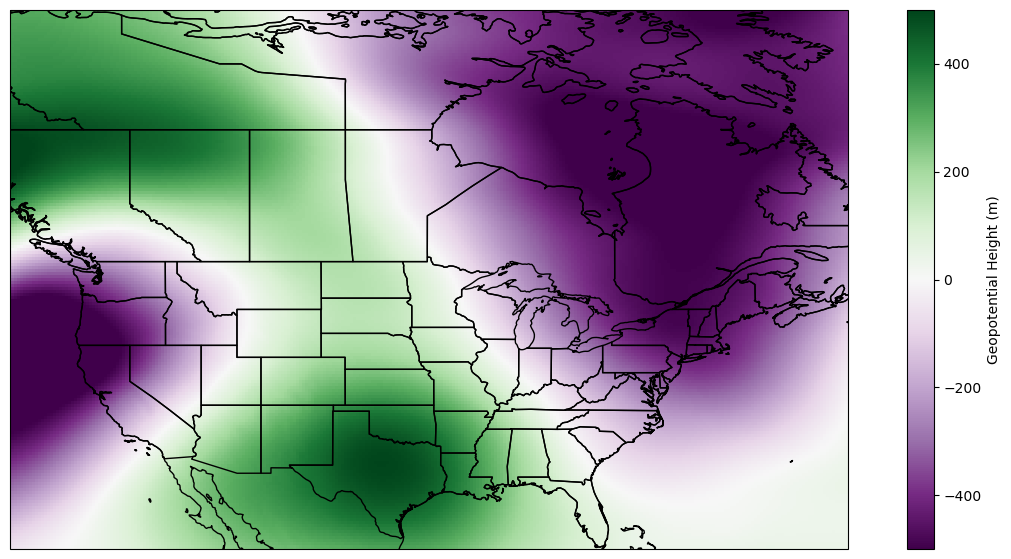

In [29]:
#GEO HEIGHT MAP: just look at first time step to see if data is showing up

june_hgt_2d = june_hgt[0, :, :]

lon = june_hgt.longitude
lat = june_hgt.latitude

f = plt.figure(figsize=(15,7))
ax = plt.subplot(projection=ccrs.PlateCarree())
CS = plt.pcolormesh(lon, lat, june_hgt_2d,  # Use the 2D slice
                    cmap=plt.cm.PRGn, 
                    vmin=-500, vmax=500, 
                    transform=ccrs.PlateCarree())
plt.xlabel('Longitude')
plt.ylabel('Latitude')
ax.coastlines()
ax.set_extent([-130, -60, 25, 70], crs=ccrs.PlateCarree())
ax.add_feature(cfeature.STATES)
cb = plt.colorbar(CS, ax=ax)
cb.set_label('Geopotential Height (m)')
plt.show()

In [30]:
vmin = np.nanmin(june_uwinds)
vmax = np.nanmax(june_uwinds)

print(f"vmin: {vmin}")
print(f"vmax: {vmax}")

vmin: -11.183053016662598
vmax: 11.040528297424316


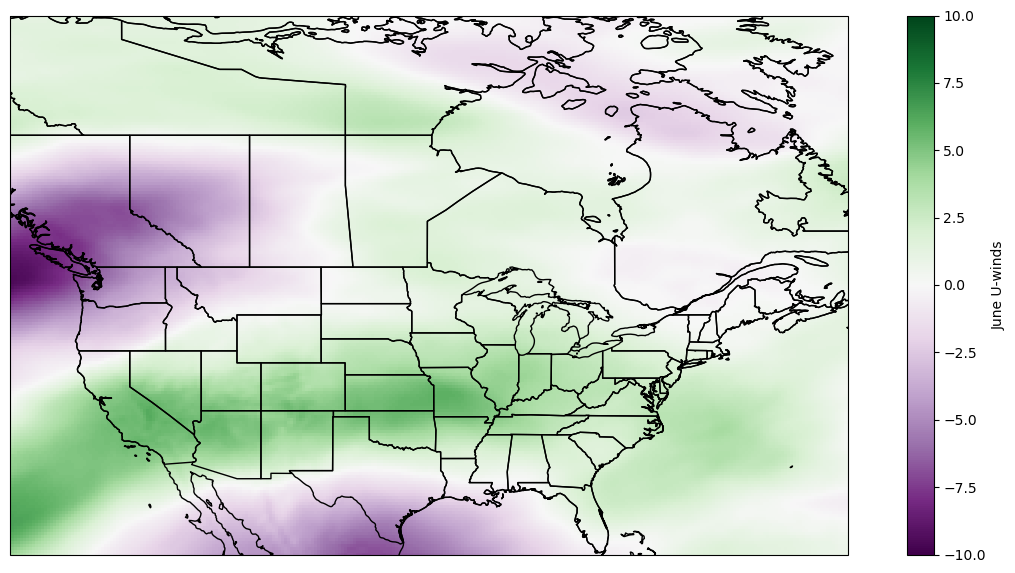

In [31]:
#WIND MAP: just look at first time step to see if data is showing up

june_uwinds_2d = june_uwinds[0, :, :]

f = plt.figure(figsize=(15,7))
ax = plt.subplot(projection=ccrs.PlateCarree())
CS = plt.pcolormesh(lon, lat, june_uwinds_2d,  # Use the 2D slice
                    cmap=plt.cm.PRGn, 
                    vmin=-10, vmax=10, 
                    transform=ccrs.PlateCarree())
plt.xlabel('Longitude')
plt.ylabel('Latitude')
ax.coastlines()
ax.set_extent([-130, -60, 25, 70], crs=ccrs.PlateCarree())
ax.add_feature(cfeature.STATES)
cb = plt.colorbar(CS, ax=ax)
cb.set_label('June U-winds')
plt.show()

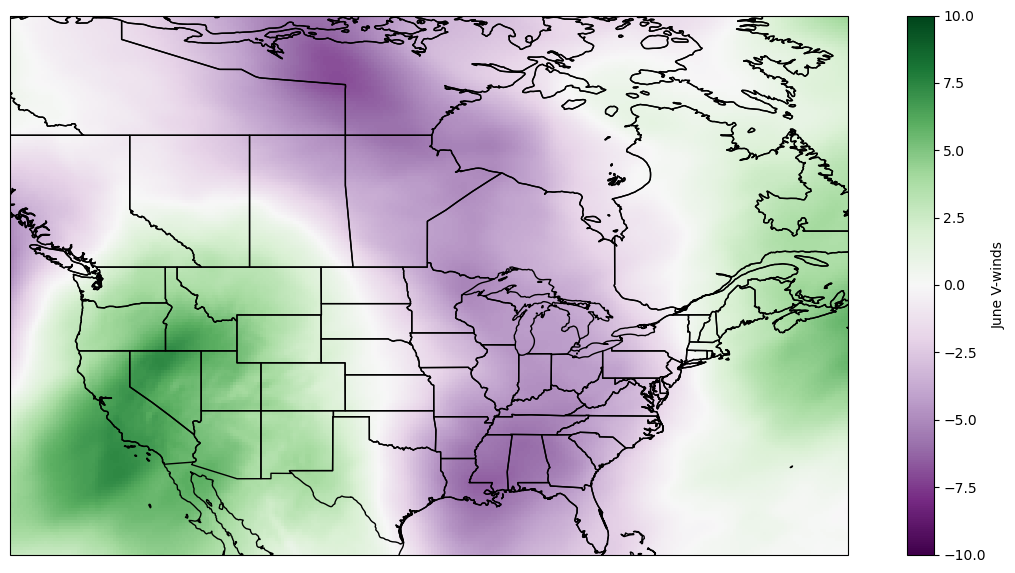

In [32]:
june_vwinds_2d = june_vwinds[0, :, :]

f = plt.figure(figsize=(15,7))
ax = plt.subplot(projection=ccrs.PlateCarree())
CS = plt.pcolormesh(lon, lat, june_vwinds_2d,  # Use the 2D slice
                    cmap=plt.cm.PRGn, 
                    vmin=-10, vmax=10, 
                    transform=ccrs.PlateCarree())
plt.xlabel('Longitude')
plt.ylabel('Latitude')
ax.coastlines()
ax.set_extent([-130, -60, 25, 70], crs=ccrs.PlateCarree())
ax.add_feature(cfeature.STATES)
cb = plt.colorbar(CS, ax=ax)
cb.set_label('June V-winds')
plt.show()

# 3. Regional lake index

In [15]:
# COARSEN the geopotential height grid (0.25° → 1° resolution)
#I dont need so much detail when just looking for teleconnection patterns

june_hgt_coarse = june_hgt.coarsen(latitude=4, longitude=4, boundary='trim').mean()
print(f"Original shape: {june_hgt.shape}")
print(f"Coarsened shape: {june_hgt_coarse.shape}")

Original shape: (41, 181, 281)
Coarsened shape: (41, 45, 70)


In [16]:
#load lake data and find common years ───────────────────────────────────

lake_df = pd.read_csv('lake_VHT.csv')

lake_pivot = lake_df.pivot(index='year', columns='lagoslakeid', values='VHT')

common_years = np.intersect1d(
    june_hgt_coarse.valid_time.dt.year.values,
    lake_pivot.index.values
)

june_hgt_common  = june_hgt_coarse.sel(
    valid_time=june_hgt_coarse.valid_time.dt.year.isin(common_years)
)

lake_pivot_common = lake_pivot.loc[common_years]

#CREATE A MINNESOTA-WIDE lake VHT index (mean across lakes each year)
vht_index = lake_pivot_common.mean(axis=1).values

n_years = len(common_years)
n_lat   = len(june_hgt_common.latitude)
n_lon   = len(june_hgt_common.longitude)
lats    = june_hgt_common.latitude.values
lons    = june_hgt_common.longitude.values

hgt_reshaped = june_hgt_common.values.reshape(n_years, -1)

print(f"Common years: {common_years.min()}–{common_years.max()}, n={n_years}")
print(f"Grid: {n_lat} lat × {n_lon} lon")

Common years: 1980–2020, n=41
Grid: 45 lat × 70 lon


In [17]:
#create a spatial grid ────────────────────────────────────
lake_completeness = lake_pivot_common.notna().sum().sort_values(ascending=False)

lake_coords = lake_df.drop_duplicates(subset='lagoslakeid')[
    ['lagoslakeid', 'latitude', 'longitude']
].set_index('lagoslakeid')

lake_info = pd.DataFrame({'n_years': lake_completeness}).join(lake_coords)

lat_bins = np.arange(43.5, 50.0, 1.0)
lon_bins = np.arange(-97.5, -89.5, 2.0)

lake_info['lat_bin'] = pd.cut(lake_info['latitude'],  bins=lat_bins, labels=False)
lake_info['lon_bin'] = pd.cut(lake_info['longitude'], bins=lon_bins, labels=False)
lake_info['cell']    = lake_info['lat_bin'].astype(str) + '_' + lake_info['lon_bin'].astype(str)


In [18]:
#select lakes across the grid ─────────────────────────────────────
min_years      = 7
lakes_per_cell = 2

spatially_selected = (
    lake_info[lake_info['n_years'] >= min_years]
    .sort_values('n_years', ascending=False)
    .groupby('cell')
    .head(lakes_per_cell)
    .reset_index()
)

print(f"\nSelected {len(spatially_selected)} lakes across {spatially_selected['cell'].nunique()} grid cells")
print(f"Record length range: {spatially_selected['n_years'].min()}–{spatially_selected['n_years'].max()} years")



Selected 22 lakes across 13 grid cells
Record length range: 7–38 years


Loading Minnesota ECS Sections from ArcGIS...
Loaded 11 ECS sections


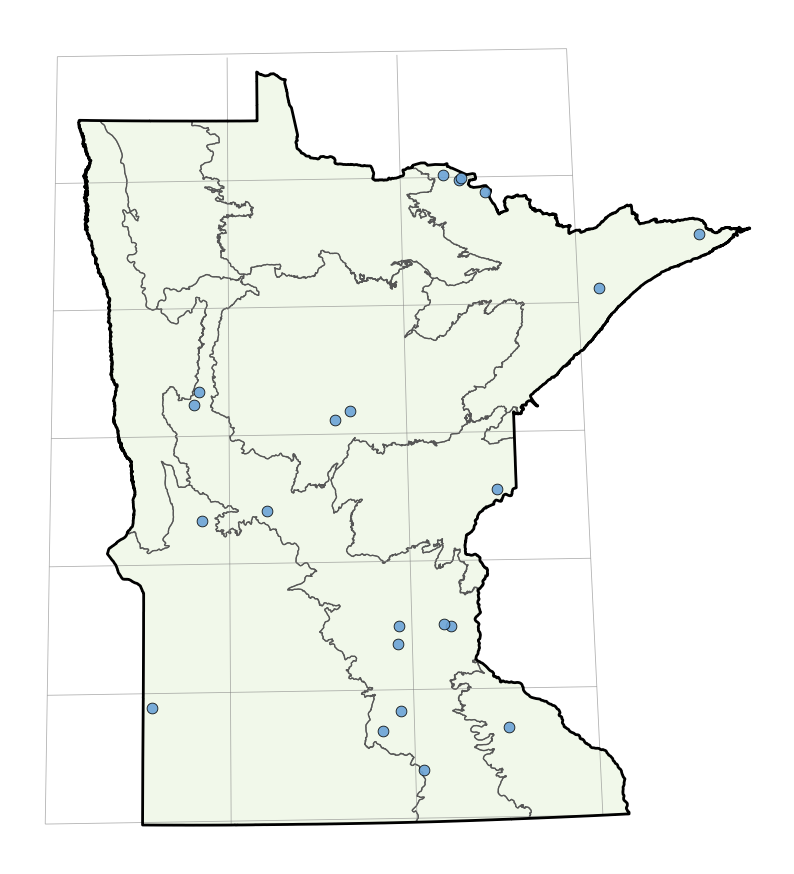

In [19]:
#create a map for publicaton supplemental materials

#load Minnesota boundary from arcgis
print("Loading Minnesota ECS Sections from ArcGIS...")
try:
    url = "https://services.arcgis.com/8df8p0NlLFEShl0r/arcgis/rest/services/Ecological_Classification_System_Sections/FeatureServer/0/query"
    params = {'where': '1=1', 'outFields': '*', 'f': 'geojson'}
    response = requests.get(url, params=params)
    with open('temp_ecs.geojson', 'w') as f:
        f.write(response.text)
    minnesota = gpd.read_file('temp_ecs.geojson')
    print(f"Loaded {len(minnesota)} ECS sections")
    minnesota_boundary = minnesota.dissolve()
except Exception as e:
    print(f"Error loading from ArcGIS: {e}")
    from shapely.geometry import box
    minnesota = gpd.GeoDataFrame({'geometry': [box(-97.5, 43.5, -89.5, 49.5)]}, crs='EPSG:4326')
    minnesota_boundary = minnesota

TARGET_CRS = 5070

#project polygon and points

minnesota_proj = minnesota.to_crs(epsg=TARGET_CRS)
minnesota_boundary_proj = minnesota_boundary.to_crs(epsg=TARGET_CRS)

lakes_gdf = gpd.GeoDataFrame(
    spatially_selected.copy(),
    geometry=gpd.points_from_xy(spatially_selected["longitude"], spatially_selected["latitude"]),
    crs="EPSG:4326"
).to_crs(epsg=TARGET_CRS)

#build grid lines
grid_lines = []
for x in lon_bins:
    line = gpd.GeoSeries(
        [__import__("shapely.geometry", fromlist=["LineString"]).LineString(
            [(x, lat_bins.min()), (x, lat_bins.max())]
        )], crs="EPSG:4326"
    ).to_crs(epsg=TARGET_CRS)
    grid_lines.append(line)
for y in lat_bins:
    line = gpd.GeoSeries(
        [__import__("shapely.geometry", fromlist=["LineString"]).LineString(
            [(lon_bins.min(), y), (lon_bins.max(), y)]
        )], crs="EPSG:4326"
    ).to_crs(epsg=TARGET_CRS)
    grid_lines.append(line)

#figure/basemap
fig, ax = plt.subplots(figsize=(10, 12))
ax.set_facecolor("white")
fig.patch.set_facecolor("white")

minnesota_proj.plot(ax=ax, color="#F1F8E9", alpha=0.95, zorder=1)
minnesota_proj.boundary.plot(ax=ax, edgecolor="#555555", linewidth=0.9, alpha=0.9, zorder=2)
minnesota_boundary_proj.boundary.plot(ax=ax, edgecolor="black", linewidth=2.0, zorder=3)

for line in grid_lines:
    line.plot(ax=ax, color="gray", linewidth=0.6, alpha=0.6, zorder=2)

ax.scatter(
    lakes_gdf.geometry.x,
    lakes_gdf.geometry.y,
    c="#6BA3D6",
    marker="o",
    s=60,
    edgecolors="black",
    linewidths=0.6,
    alpha=0.9,
    zorder=5
)

ax.set_aspect("equal")
ax.set_axis_off()
for spine in ax.spines.values():
    spine.set_visible(False)
ax.grid(False)

plt.savefig("MN_spatialgridmap.png", dpi=300, bbox_inches="tight", facecolor=fig.get_facecolor())
plt.show()

In [20]:
#build a spatial lake index───────────────────────────────────────────────
selected_ids = spatially_selected['lagoslakeid'].values
lake_pivot_spatial = lake_pivot_common[
    [l for l in selected_ids if l in lake_pivot_common.columns]
]
lake_index_spatial = np.nanmean(lake_pivot_spatial.values, axis=1)

In [21]:
#narrow down to 'reliable period' (≥10 lakes per year) ──────────────────────
lakes_per_year  = lake_pivot_spatial.notna().sum(axis=1)
reliable_years  = lakes_per_year[lakes_per_year >= 10].index.values
reliable_mask   = np.isin(common_years, reliable_years)

lake_index_rel   = lake_index_spatial[reliable_mask]
hgt_reshaped_rel = hgt_reshaped[reliable_mask, :]
common_years_rel = common_years[reliable_mask]

print(f"\nReliable period: {reliable_years.min()}–{reliable_years.max()}, n={len(reliable_years)} years")


Reliable period: 1994–2020, n=17 years


In [27]:
print(lake_index_rel)

[4.10983013 2.325      1.07585424 4.46983879 4.78997047 6.63785834
 6.4671     4.44280301 5.37914583 4.96130003 4.86406224 6.44971623
 5.80212338 4.43531234 7.80810189 4.5485075  7.09562293]


In [28]:
# Save reliable-period lake index with corresponding years
regional_lake_index = pd.DataFrame({
    "common_years_rel": common_years_rel,
    "lake_index_rel": lake_index_rel
})

regional_lake_index.to_csv(
    "regional_lake_index.csv",
    index=False
)

print(f"Saved {len(regional_lake_index)} years to regional_lake_index.csv")
print(regional_lake_index)


Saved 17 years to regional_lake_index.csv
    common_years_rel  lake_index_rel
0               1994        4.109830
1               1995        2.325000
2               1998        1.075854
3               2006        4.469839
4               2007        4.789970
5               2008        6.637858
6               2009        6.467100
7               2010        4.442803
8               2011        5.379146
9               2012        4.961300
10              2013        4.864062
11              2014        6.449716
12              2015        5.802123
13              2016        4.435312
14              2017        7.808102
15              2018        4.548508
16              2020        7.095623


In [22]:
#correlate all grid points against spatial lake index ─────────────────
correlation_map = np.full(n_lat * n_lon, np.nan)
pvalue_map      = np.full(n_lat * n_lon, np.nan)
lake_valid_rel  = ~np.isnan(lake_index_rel)

start_time = time.time()
print("\nCalculating correlations (reliable period)...")

for grid_idx in range(n_lat * n_lon):
    hgt_ts     = hgt_reshaped_rel[:, grid_idx]
    valid_mask = lake_valid_rel & ~np.isnan(hgt_ts)
    if valid_mask.sum() < 10:
        continue
    try:
        corr, pval          = pearsonr(hgt_ts[valid_mask], lake_index_rel[valid_mask])
        correlation_map[grid_idx] = corr
        pvalue_map[grid_idx]      = pval
    except Exception:
        continue

correlation_map = correlation_map.reshape(n_lat, n_lon)
pvalue_map      = pvalue_map.reshape(n_lat, n_lon)

print(f"✓ Completed in {time.time() - start_time:.1f} seconds")
print(f"  Max r: {np.nanmax(correlation_map):.3f}")
print(f"  Min r: {np.nanmin(correlation_map):.3f}")
print(f"  Significant grid points (p<0.05): {np.sum(pvalue_map < 0.05)}")


Calculating correlations (reliable period)...
✓ Completed in 0.2 seconds
  Max r: 0.352
  Min r: -0.622
  Significant grid points (p<0.05): 180


# 5. Processing of air temp and precip ERA5-Land data into USGS HUC 12 boundaries

## Pull in MN HUC 12 data

In [105]:
from pathlib import Path

urls = {
    "04": "https://prd-tnm.s3.amazonaws.com/StagedProducts/Hydrography/WBD/HU2/Shape/WBD_04_HU2_Shape.zip",
    "07": "https://prd-tnm.s3.amazonaws.com/StagedProducts/Hydrography/WBD/HU2/Shape/WBD_07_HU2_Shape.zip",
    "09": "https://prd-tnm.s3.amazonaws.com/StagedProducts/Hydrography/WBD/HU2/Shape/WBD_09_HU2_Shape.zip",
}

download_root = Path("huc12_downloads")

for region, url in urls.items():
    print(f"Downloading HU2 {region}…")
    r = requests.get(url)
    target = download_root / f"huc12_region{region}"
    target.mkdir(parents=True, exist_ok=True)
    with ZipFile(BytesIO(r.content)) as z:
        z.extractall(target)

NameError: name 'Path' is not defined

In [3]:
from pathlib import Path

root = Path("huc12_downloads")

files = [
    root / "huc12_region04" / "Shape" / "WBDHU12.shp",
    root / "huc12_region07" / "Shape" / "WBDHU12.shp",
    root / "huc12_region09" / "Shape" / "WBDHU12.shp",
]

gdfs = [gpd.read_file(p) for p in files]

huc12_all = gpd.GeoDataFrame(pd.concat(gdfs, ignore_index=True), crs=gdfs[0].crs)

## Now read and shape

In [4]:
# MN boundary from Census
mn = gpd.read_file(
    "https://www2.census.gov/geo/tiger/GENZ2018/shp/cb_2018_us_state_500k.zip"
)
mn = mn[mn["STUSPS"] == "MN"][["geometry"]]

# Reproject to common CRS
mn = mn.to_crs(huc12_all.crs)

# Exact clip
huc12_mn = gpd.overlay(huc12_all, mn, how="intersection")

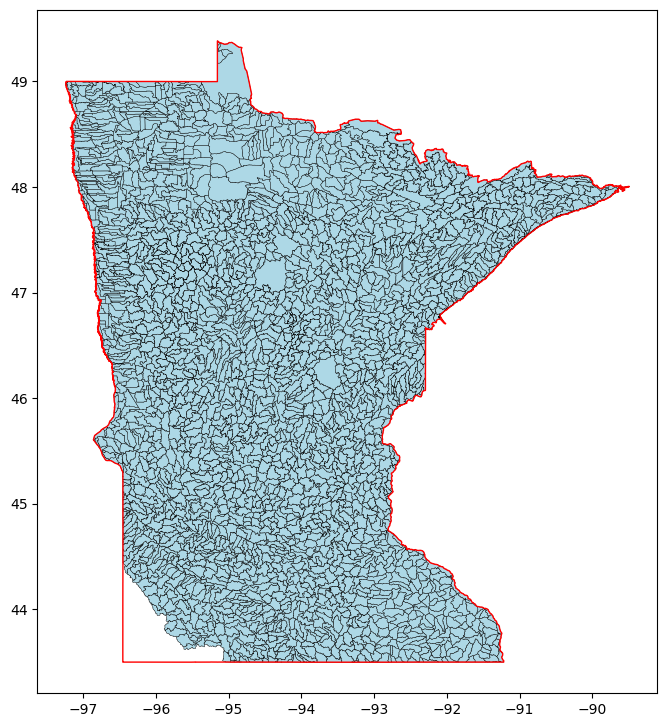

In [5]:
fig, ax = plt.subplots(figsize=(8,10))
mn.boundary.plot(ax=ax, color="red", lw=1)
huc12_mn.plot(ax=ax, edgecolor="black", facecolor="lightblue", linewidth=0.3)
plt.show()

In [6]:
# Check the coordinate reference system
print("CRS:", huc12_mn.crs)

# Check how many are purely in Minnesota vs border watersheds
print("\nWatersheds by state:")
print(huc12_mn['states'].value_counts())

CRS: EPSG:4269

Watersheds by state:
states
MN             2214
CN,MN            60
IA,MN            41
MN,WI            38
MN,ND            31
MN,SD            30
CN,MI,MN,WI       2
CN,MI,MN          1
IA,MN,WI          1
MN,ND,SD          1
CN,MN,ND          1
Name: count, dtype: int64


## Pull in lake data and assign to grids and HUC12

In [40]:
#load in lake data
lakes_df = pd.read_csv('unique_lakeIDs.csv')

# Create point geometries from lat/lon
geometry = [Point(xy) for xy in zip(lakes_df['longitude'], lakes_df['latitude'])]

# Create GeoDataFrame
lakes_gdf = gpd.GeoDataFrame(
    lakes_df, 
    geometry=geometry,
    crs='EPSG:4326'  # Lat/lon are typically in WGS84
)

# Reproject lakes to match HUC12 CRS
lakes_gdf = lakes_gdf.to_crs(huc12_mn.crs)

print(f"Loaded {len(lakes_gdf)} lakes")

Loaded 463 lakes


In [41]:
#assign each lake to its HUC12

lakes_with_huc = gpd.sjoin(
    lakes_gdf, 
    huc12_mn[['huc12', 'name', 'geometry']], 
    how='left', 
    predicate='within'
)

# Check results
print(f"Lakes matched to watersheds: {lakes_with_huc['huc12'].notna().sum()}")
print(f"Lakes without watershed match: {lakes_with_huc['huc12'].isna().sum()}")

Lakes matched to watersheds: 460
Lakes without watershed match: 3


In [42]:
#investigate the unmatched lakes...

# Find the lake without a watershed match
unmatched_lake = lakes_with_huc[lakes_with_huc['huc12'].isna()]
print("Unmatched lake:")
print(unmatched_lake[['lagoslakeid', 'longitude', 'latitude']])

Unmatched lake:
     lagoslakeid  longitude   latitude
56           921 -92.465463  48.387979
436       119044 -92.606199  48.443187
459       140519 -92.405971  48.279708


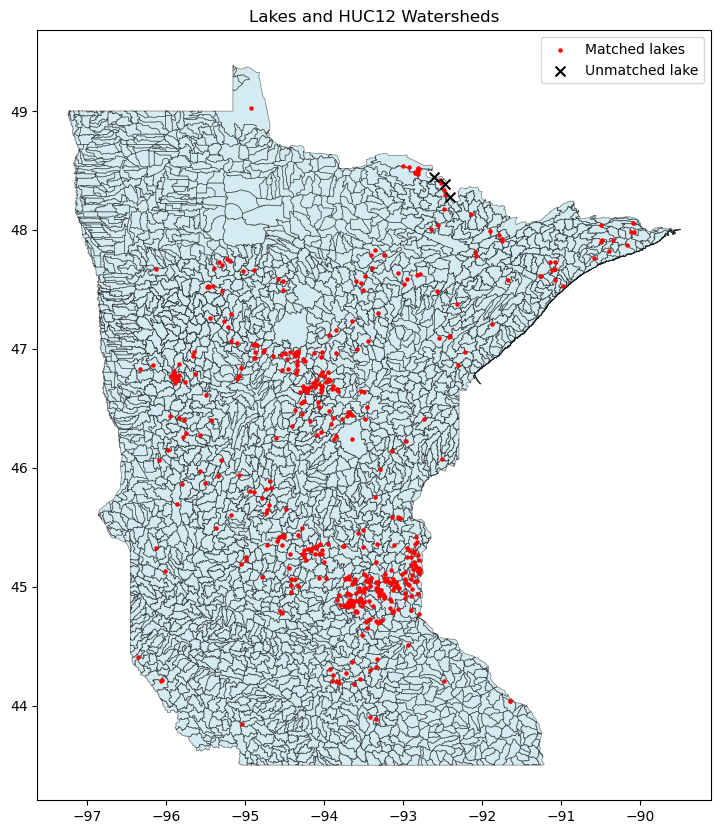

In [43]:
#shows where unmatched lake is, but then i edited it to save as a figure instead

fig, ax = plt.subplots(figsize=(12, 10))

# Plot all HUC12 watersheds
huc12_mn.plot(ax=ax, edgecolor='black', facecolor='lightblue', linewidth=0.5, alpha=0.5)

# Plot matched lakes in green
matched_lakes = lakes_with_huc[lakes_with_huc['huc12'].notna()]
matched_lakes.plot(ax=ax, color='red', markersize=5, label='Matched lakes')

#Plot unmatched lake in red
unmatched_lake.plot(ax=ax, color='black', markersize=50, label='Unmatched lake', marker='x')

ax.legend()
ax.set_title('Lakes and HUC12 Watersheds')
plt.savefig('lakes_huc12_map.png', dpi=300, bbox_inches='tight')
plt.show()

In [44]:
# Find the nearest HUC12 watershed for all unmatched lakes
if len(unmatched_lake) > 0:
    # Project to UTM Zone 15N (appropriate for Minnesota) for accurate distance calculation
    huc12_utm = huc12_mn.to_crs('EPSG:26915')  # UTM Zone 15N
    unmatched_utm = unmatched_lake.to_crs('EPSG:26915')

    print(f"\nFinding nearest HUC12 for {len(unmatched_lake)} unmatched lakes...")

    for idx, row in unmatched_utm.iterrows():
        # Get the unmatched lake point
        unmatched_point = row.geometry

        # Calculate distance to all HUC12 watersheds (in meters)
        huc12_utm['distance'] = huc12_utm.geometry.distance(unmatched_point)

        # Find nearest watershed
        nearest_huc = huc12_utm.loc[huc12_utm['distance'].idxmin()]

        print(f"\nNearest HUC12 to unmatched lake (index {idx}):")
        print(f"  HUC12 ID: {nearest_huc['huc12']}")
        print(f"  Name:     {nearest_huc['name']}")
        print(f"  Distance: {nearest_huc['distance']:.2f} meters")

        # Assign the unmatched lake to nearest watershed in the original dataframe
        lakes_with_huc.loc[idx, 'huc12'] = nearest_huc['huc12']
        lakes_with_huc.loc[idx, 'name'] = nearest_huc['name']

    print("\n✓ Assigned all unmatched lakes to nearest watersheds")
    print(f"All lakes now matched: {lakes_with_huc['huc12'].notna().all()}")


Finding nearest HUC12 for 3 unmatched lakes...

Nearest HUC12 to unmatched lake (index 56):
  HUC12 ID: 090300012602
  Name:     Sand Point Lake
  Distance: 3.21 meters

Nearest HUC12 to unmatched lake (index 436):
  HUC12 ID: 090300012605
  Name:     Namakan Lake
  Distance: 434.32 meters

Nearest HUC12 to unmatched lake (index 459):
  HUC12 ID: 090300012104
  Name:     Loon River-Little Vermilion Lake
  Distance: 65.32 meters

✓ Assigned all unmatched lakes to nearest watersheds
All lakes now matched: True


In [45]:
huc12_era5_crs = huc12_mn.to_crs('EPSG:4326')
huc12_with_lakes = lakes_with_huc['huc12'].dropna().unique()

huc12_sub = huc12_mn[huc12_mn['huc12'].isin(huc12_with_lakes)].to_crs('EPSG:4326')
print(f"HUC12 watersheds with lakes: {len(huc12_sub)}")

years = range(1980, 2021)

# Standalone months
standalone_months = [
    (4, 'April'),
    (5, 'May'),
    (6, 'June'),
]

# Months to average together into JA
ja_months = [(7, 'July'), (8, 'August')]

print(f"HUC12 watersheds to process: {len(huc12_with_lakes)}")
print(f"Years: {min(years)}–{max(years)}")

HUC12 watersheds with lakes: 270
HUC12 watersheds to process: 270
Years: 1980–2020


In [46]:
#clip ERA5 to MN bounding box to reduce memory
bounds = huc12_sub.total_bounds  # [minx, miny, maxx, maxy]
airtemp     = airtemp.sel(
    longitude=slice(bounds[0], bounds[2]),
    latitude=slice(bounds[3], bounds[1])   # ERA5 lat is N→S
)
totalprecip = totalprecip.sel(
    longitude=slice(bounds[0], bounds[2]),
    latitude=slice(bounds[3], bounds[1])
)

#make REGIONMASK ─────────────────────────────────────────────────────────────
huc12_regions = regionmask.from_geopandas(
    huc12_sub.reset_index(drop=True),
    names='huc12',
    name='huc12_regions'
)

#pass coordinate names explicitly
huc12_mask = huc12_regions.mask(
    airtemp.longitude,
    airtemp.latitude
)

In [47]:
# 4. VECTORIZED CLIMATE EXTRACTION ──────────────────────────────────────────
# Filter to months of interest
months_of_interest = [4, 5, 6, 7, 8]
airtemp_filt     = airtemp.sel(
    valid_time=airtemp.valid_time.dt.month.isin(months_of_interest)
)
totalprecip_filt = totalprecip.sel(
    valid_time=totalprecip.valid_time.dt.month.isin(months_of_interest)
)

records = []
for region_idx, huc_id in enumerate(huc12_sub['huc12'].values):
    # Boolean mask for this HUC12's ERA5 cells
    cell_mask = huc12_mask == region_idx

    # Skip if no ERA5 cells fall inside this HUC12 (too small)
    if not cell_mask.any():
        continue

    # Spatial mean over only this HUC12's cells — shape (valid_time,)
    temp_ts   = (airtemp_filt.where(cell_mask)
                              .mean(dim=['latitude', 'longitude'])) - 273.15
    precip_ts = (totalprecip_filt.where(cell_mask)
                                  .mean(dim=['latitude', 'longitude']))

    # Build a tidy dataframe for this HUC12
    df = pd.DataFrame({
        'huc12':    huc_id,
        'year':     airtemp_filt.valid_time.dt.year.values,
        'month':    airtemp_filt.valid_time.dt.month.values,
        'temp_c':   temp_ts.values,
        'precip_m': precip_ts.values,
    })
    records.append(df)

huc12_climate_df = pd.concat(records, ignore_index=True)

In [48]:
# MONTH LABELS + JA AGGREGATION ──────────────────────────────────────────
month_map = {4: 'April', 5: 'May', 6: 'June', 7: 'July', 8: 'August'}
huc12_climate_df['month_name'] = huc12_climate_df['month'].map(month_map)

# Standalone months (Apr, May, Jun) — keep as-is
standalone = huc12_climate_df[huc12_climate_df['month'].isin([4, 5, 6])].copy()
standalone['month'] = standalone['month'].map({4:'April', 5:'May', 6:'June'})
standalone = standalone.drop(columns=['month_name'])

# JA: average temp, SUM precip across July + August per HUC12 per year
ja = (huc12_climate_df[huc12_climate_df['month'].isin([7, 8])]
      .groupby(['huc12', 'year'], as_index=False)
      .agg(temp_c=('temp_c', 'mean'),
           precip_m=('precip_m', 'mean'))   # mean Jul+Aug precip
)
ja['month'] = 'JA'

huc12_climate_final = pd.concat([standalone, ja], ignore_index=True)
print(f"Total climate records: {len(huc12_climate_final)}")

Total climate records: 35096


In [49]:
# ASSIGN TO LAKES & SAVE ─────────────────────────────────────────────────
lakes_final_long = (lakes_with_huc[['lagoslakeid', 'huc12', 'longitude',
                                     'latitude', 'lake_area_m2']]
                    .merge(huc12_climate_final, on='huc12', how='left'))

#lakes_final_long.to_csv('lakes_with_climate_data_long.csv', index=False)

print("\nClimate summary by month:")
print(lakes_final_long.groupby('month')[['temp_c', 'precip_m']].describe())


Climate summary by month:
        temp_c                                                        \
         count       mean       std        min        25%        50%   
month                                                                  
April  14883.0   5.794513  2.742785  -2.493256   4.105255   5.996490   
JA     14883.0  21.090942  1.711652  14.348663  20.026062  21.177277   
June   14883.0  18.713943  2.147334  11.044342  17.377838  18.922760   
May    14883.0  13.206303  2.402354   5.154449  11.677887  13.261627   

                            precip_m                                          \
             75%        max    count      mean       std       min       25%   
month                                                                          
April   7.732819  12.618073  14883.0  0.073187  0.035687  0.006280  0.046016   
JA     22.334198  25.000153  14883.0  0.100353  0.030293  0.028431  0.077428   
June   20.128082  24.593903  14883.0  0.112206  0.043750  0.013876  

In [50]:
#How many unique lakes got climate data
total_lakes = lakes_with_huc['lagoslakeid'].nunique()
lakes_with_data = lakes_final_long.dropna(subset=['temp_c','precip_m'])['lagoslakeid'].nunique()
print(f"Lakes with climate data: {lakes_with_data}/{total_lakes} ({100*lakes_with_data/total_lakes:.1f}%)")

#Which lakes are missing data entirely?
missing_lakes = lakes_final_long[lakes_final_long['temp_c'].isna()]['lagoslakeid'].unique()
print(f"Lakes missing all climate data: {len(missing_lakes)}")

# Check expected record count per lake
# Should be: 41 years × 5 periods (Apr,May,Jun,JA) = 205 records per lake
records_per_lake = lakes_final_long.groupby('lagoslakeid').size()
print(f"\nRecords per lake — expected 205:")
print(records_per_lake.describe())
print(f"Lakes with < 205 records: {(records_per_lake < 205).sum()}")

# Check which months are present
print(f"\nMonths present: {sorted(lakes_final_long['month'].dropna().unique())}")
print(lakes_final_long.groupby('month')['lagoslakeid'].nunique())

# Lakes missing due to HUC12 assignment failure (no huc12 match)
no_huc = lakes_with_huc[lakes_with_huc['huc12'].isna()]['lagoslakeid'].nunique()
print(f"\nLakes with no HUC12 match: {no_huc}")

# Lakes in HUC12s that had no ERA5 cells (too small)
huc12_in_climate = huc12_climate_final['huc12'].unique()
lakes_no_era5 = lakes_with_huc[
    lakes_with_huc['huc12'].notna() & 
    ~lakes_with_huc['huc12'].isin(huc12_in_climate)
]['lagoslakeid'].nunique()
print(f"Lakes in HUC12s with no ERA5 coverage: {lakes_no_era5}")

Lakes with climate data: 363/463 (78.4%)
Lakes missing all climate data: 100

Records per lake — expected 205:
count    463.000000
mean     128.794816
std       67.147436
min        1.000000
25%      164.000000
50%      164.000000
75%      164.000000
max      164.000000
dtype: float64
Lakes with < 205 records: 463

Months present: ['April', 'JA', 'June', 'May']
month
April    363
JA       363
June     363
May      363
Name: lagoslakeid, dtype: int64

Lakes with no HUC12 match: 0
Lakes in HUC12s with no ERA5 coverage: 100


In [51]:
# Identify HUC12s with no ERA5 coverage ─────────────────────────────────────
huc12_in_climate = huc12_climate_final['huc12'].unique()
huc12_no_coverage = huc12_sub[~huc12_sub['huc12'].isin(huc12_in_climate)].copy()
print(f"HUC12s needing nearest-cell fallback: {len(huc12_no_coverage)}")

# Get centroid of each small HUC12 ──────────────────────────────────────────
# Project to planar CRS for accurate centroid, then back to WGS84
huc12_no_coverage = huc12_no_coverage.to_crs('EPSG:26915')  # UTM Zone 15N (Minnesota)
huc12_no_coverage['centroid'] = huc12_no_coverage.geometry.centroid
huc12_no_coverage = huc12_no_coverage.to_crs('EPSG:4326')

# Now extract centroid coords in WGS84
huc12_no_coverage['cx'] = huc12_no_coverage['centroid'].apply(lambda g: g.x)
huc12_no_coverage['cy'] = huc12_no_coverage['centroid'].apply(lambda g: g.y)

# Extract nearest ERA5 cell for each small HUC12 ────────────────────────────
fallback_records = []
for _, row in huc12_no_coverage.iterrows():
    temp_near = airtemp_filt.sel(
        longitude=row['cx'], 
        latitude=row['cy'],
        method='nearest'
    )
    precip_near = totalprecip_filt.sel(
        longitude=row['cx'],
        latitude=row['cy'],
        method='nearest'
    )
    df = pd.DataFrame({
        'huc12':    row['huc12'],
        'year':     airtemp_filt.valid_time.dt.year.values,
        'month':    airtemp_filt.valid_time.dt.month.values,
        'temp_c':   temp_near.values - 273.15,
        'precip_m': precip_near.values,
    })
    fallback_records.append(df)

fallback_df = pd.concat(fallback_records, ignore_index=True)

# Apply same month labelling and JA aggregation ─────────────────────────────
fallback_standalone = fallback_df[fallback_df['month'].isin([4, 5, 6])].copy()
fallback_standalone['month'] = fallback_standalone['month'].map(
    {4:'April', 5:'May', 6:'June'}
)

fallback_ja = (fallback_df[fallback_df['month'].isin([7, 8])]
               .groupby(['huc12', 'year'], as_index=False)
               .agg(temp_c=('temp_c', 'mean'),
                    precip_m=('precip_m', 'mean'))
)
fallback_ja['month'] = 'JA'

fallback_final = pd.concat([fallback_standalone, fallback_ja], ignore_index=True)

# Combine with main climate data and re-merge to lakes ──────────────────────
huc12_climate_complete = pd.concat(
    [huc12_climate_final, fallback_final], ignore_index=True
)

lakes_final_long = (lakes_with_huc[['lagoslakeid', 'huc12', 'longitude',
                                     'latitude', 'lake_area_m2']]
                    .merge(huc12_climate_complete, on='huc12', how='left'))

# Verify ────────────────────────────────────────────────────────────────────
total = lakes_with_huc['lagoslakeid'].nunique()
covered = lakes_final_long.dropna(subset=['temp_c','precip_m'])['lagoslakeid'].nunique()
print(f"Lakes with climate data: {covered}/{total} ({100*covered/total:.1f}%)")

records_per_lake = lakes_final_long.groupby('lagoslakeid').size()
print(f"Lakes with 164 records: {(records_per_lake == 164).sum()}/{total}")

lakes_final_long.to_csv('lakes_with_climate_data_long.csv', index=False)

HUC12s needing nearest-cell fallback: 56
Lakes with climate data: 463/463 (100.0%)
Lakes with 164 records: 463/463


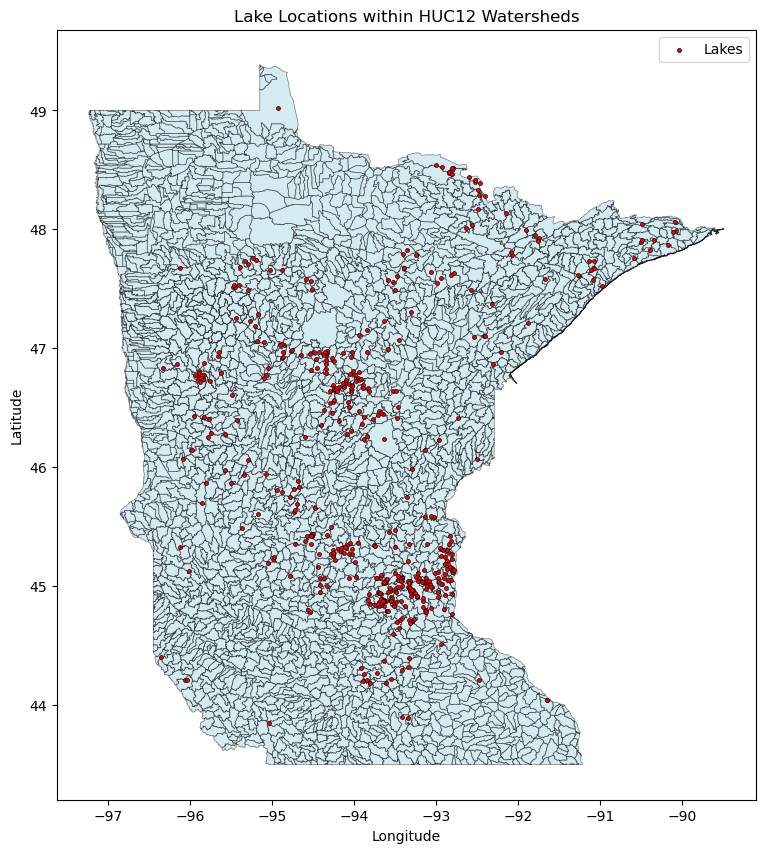

In [52]:
#map for publication

# Get lakes that have valid climate data in the final dataset
final_lake_ids = lakes_final_long.dropna(subset=['temp_c', 'precip_m'])['lagoslakeid'].unique()
lakes_final_matched = lakes_with_huc[lakes_with_huc['lagoslakeid'].isin(final_lake_ids)]

fig, ax = plt.subplots(figsize=(12, 10))

# Plot all HUC12 watersheds
huc12_mn.plot(ax=ax, edgecolor='black', facecolor='lightblue', linewidth=0.5, alpha=0.5)

# Plot final matched lakes
lakes_final_matched.plot(ax=ax, color='red', edgecolor='black', linewidth=0.5, markersize=8, label='Lakes')

ax.legend()
ax.set_title('Lake Locations within HUC12 Watersheds')
ax.set_xlabel('Longitude')
ax.set_ylabel('Latitude')

plt.savefig('lakes_huc12_map.png', dpi=300, bbox_inches='tight')
plt.show()